# 02 · RQ2: Do path claims stay accurate as the code changes?

We follow every claim that was **valid when written** (its path existed at the commit that added it) up to the snapshot. Its **checkpoints** are the commit where it was written, the commit where it was removed from the file, the last commit that touched its path, and the snapshot.

Uses: `data/processed/path_claims.csv`, `context_files.csv`.

In [1]:
import os, sys; sys.path.insert(0, '../src' if os.path.basename(os.getcwd()) == 'notebooks' else 'src')
from analysis_helpers import *   # moves to the package root and loads helpers
claims = load('path_claims', parse_dates=['written_at', 'removed_from_file_at', 'path_removed_at', 'snapshot_at'])
valid = claims[claims.valid_when_written].copy()
valid['stale'] = valid.history_outcome.isin(['stale_fixed', 'stale_unfixed'])
days = lambda a, b: (a - b).dt.total_seconds() / 86400
N = {}

## 1 · What happened to claims that were valid when written (Table VI)

In [2]:
t = pd.crosstab(valid.history_outcome, valid.document, margins=True)
N['outcomes'] = t.to_dict()
t

document,context_file,readme,All
history_outcome,,,
deleted_while_valid,4776,271,5047
stale_fixed,706,63,769
stale_unfixed,445,12,457
still_valid,38805,1607,40412
All,44732,1953,46685


## 2 · How fast do claims go stale?

Claims were followed for different lengths of time, so we also count **claim-months**: one claim followed for one month counts as one claim-month. A claim is followed until it is removed from the file, or until the snapshot.

In [3]:
end = valid.removed_from_file_at.fillna(valid.snapshot_at)
valid['months'] = days(end, valid.written_at) / 30.44
g = valid.groupby('document')
rate = pd.DataFrame({'valid when written': g.size(), 'went stale': g.stale.sum(), 'share stale': g.stale.mean(),
                     'median months followed': g.months.median(), 'stale per 100 claim-months': g.stale.sum() / g.months.sum() * 100})
N['staleness'] = rate.to_dict()
rate.style.format({'share stale': '{:.1%}', 'median months followed': '{:.1f}', 'stale per 100 claim-months': '{:.2f}'})

,valid when written,went stale,share stale,median months followed,stale per 100 claim-months
document,,,,,
context_file,44732,1151,2.6%,1.7,0.99
readme,1953,75,3.8%,1.2,1.74


In [4]:
pr = valid.groupby(['repo', 'document']).agg(stale=('stale', 'sum'), months=('months', 'sum')).unstack().dropna()
N['paired_rate'] = {'projects': len(pr), **{d: pr[('stale', d)].sum() / pr[('months', d)].sum() * 100 for d in ['context_file', 'readme']}}
ctxv = valid[valid.document == 'context_file']
N['projects_with_stale_claim'] = ctxv.groupby('repo').stale.any().mean()
print(N['paired_rate']); print(f"projects with >= 1 stale context-file claim: {pct(N['projects_with_stale_claim'], 0)}")

{'projects': 441, 'context_file': np.float64(1.8606435420219936), 'readme': np.float64(1.8333618876425637)}
projects with >= 1 stale context-file claim: 12%


## 3 · When do claims go stale, and how fast are they fixed? (Figure 4)

- (a) days from writing the claim to removing its path
- (b) days from removing the path to fixing the claim
- (c) days from removing the path to the snapshot, for claims still unfixed

In [5]:
st = valid[valid.stale & valid.path_removed_at.notna()]
life = days(st.path_removed_at, st.written_at); st = st.assign(life=life)
neg = int((st.life < 0).sum()); st = st[st.life >= 0]      # paths deleted and restored can look removed before writing
fixed = valid[(valid.history_outcome == 'stale_fixed') & valid.path_removed_at.notna()]
lag = days(fixed.removed_from_file_at, fixed.path_removed_at)
unf = valid[(valid.history_outcome == 'stale_unfixed') & valid.path_removed_at.notna()]
age = days(unf.snapshot_at, unf.path_removed_at)
for d in ['context_file', 'readme']:
    L, G, A = st[st.document == d].life, lag[fixed.document == d], age[unf.document == d]
    N[f'timing_{d}'] = dict(n_stale=len(L), median_days_to_stale=L.median(), q1=L.quantile(.25), q3=L.quantile(.75),
                            within_week=(L <= 7).mean(), within_month=(L <= 30).mean(), over_90=(L > 90).mean(),
                            n_fixed=len(G), fixed_same_commit=(G <= 0).mean(), fixed_same_day=(G < 1).mean(), fixed_over_30=(G > 30).mean(),
                            n_unfixed_known=len(A), median_age_unfixed=A.median())
print('excluded (impossible timeline):', neg)
pd.DataFrame({k: v for k, v in N.items() if k.startswith('timing')}).round(3)

excluded (impossible timeline): 4


,timing_context_file,timing_readme
n_stale,1065.000,72.000
median_days_to_stale,20.050,8.790
q1,3.771,3.313
q3,60.851,59.173
within_week,0.342,0.472
within_month,0.593,0.653
over_90,0.159,0.139
n_fixed,706.000,63.000
fixed_same_commit,0.612,0.635
fixed_same_day,0.754,0.873


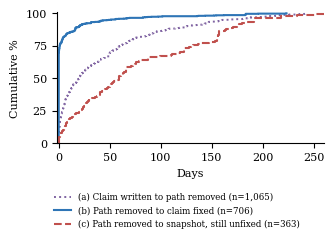

In [6]:
L, G, A = st[st.document == 'context_file'].life, lag[fixed.document == 'context_file'].clip(lower=0), age[unf.document == 'context_file']
fig, ax = plt.subplots(figsize=(FIG_W, 1.7))
def ecdf(x, **k):
    x = np.sort(np.asarray(x)); ax.step(np.r_[0, x], np.r_[0, np.arange(1, len(x) + 1) / len(x)] * 100, where='post', **k)
ecdf(L, color='#8064a2', ls=':', lw=1.4, label=f'(a) Claim written to path removed (n={len(L):,})')
ecdf(G, color='#2e75b6', label=f'(b) Path removed to claim fixed (n={len(G)})')
ecdf(A, color='#c0504d', ls='--', label=f'(c) Path removed to snapshot, still unfixed (n={len(A)})')
ax.set_xlabel('Days'); ax.set_ylabel('Cumulative %'); ax.set_xlim(-2, 260); ax.set_ylim(0, 101)
ax.legend(fontsize=6.2, frameon=False, loc='upper center', bbox_to_anchor=(0.45, -0.32))
plt.savefig(f'{FIGS}/rq2.pdf', bbox_inches='tight'); plt.show()

## 4 · Fixed or left alone?

In [7]:
s = valid[valid.stale]
fx = (s.history_outcome == 'stale_fixed').groupby(s.document).agg(['sum', 'mean'])
N['fixed'] = fx.to_dict()
allc = claims[claims.document == 'context_file']
N['projects_with_unfixed_stale'] = allc.groupby('repo').apply(lambda x: (x.history_outcome == 'stale_unfixed').any()).mean()
files = load('context_files'); fs = files[files.in_sample]
N['files_never_edited'] = (fs.n_versions == 1).mean()
print(fx); print(f"projects with an unfixed stale claim: {pct(N['projects_with_unfixed_stale'])}; files never edited: {pct(N['files_never_edited'], 0)}")

              sum     mean
document                  
context_file  706  0.61338
readme         63  0.84000
projects with an unfixed stale claim: 6.8%; files never edited: 38%


## 5 · By file, section, form and language (Table VII, columns *Stale* and *Fixed*)

In [8]:
v = valid[valid.document == 'context_file']
rows = {}
for name, mask in [('CLAUDE.md', v.file == 'CLAUDE.md'), ('AGENTS.md', v.file == 'AGENTS.md'), ('Copilot', v.file == '.github/copilot-instructions.md'),
                   ('other files', v.file.isin(['.claude/CLAUDE.md', 'GEMINI.md', '.cursorrules'])),
                   ('structure section', v.in_structure_section), ('other sections', ~v.in_structure_section),
                   ('inline', v.form == 'inline'), ('tree', v.form == 'tree'),
                   ('TS/JS/Python', v.language_group == 'TS/JS/Python'), ('other languages', v.language_group == 'other')]:
    x = v[mask]; s_ = x[x.stale]
    rows[name] = {'stale per 100 claim-months': x.stale.sum() / x.months.sum() * 100, 'share of stale fixed': (s_.history_outcome == 'stale_fixed').mean()}
pd.DataFrame(rows).T.style.format({'stale per 100 claim-months': '{:.2f}', 'share of stale fixed': '{:.0%}'})

,stale per 100 claim-months,share of stale fixed
CLAUDE.md,0.95,59%
AGENTS.md,1.20,73%
Copilot,0.77,43%
other files,0.98,58%
structure section,0.72,59%
other sections,1.53,64%
inline,1.08,63%
tree,0.70,55%
TS/JS/Python,0.82,56%
other languages,1.17,65%


In [9]:
save_numbers('rq2_numbers', N); print('saved results/rq2_numbers.json')

saved results/rq2_numbers.json
